# Lab 7- Data Analysis


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [20]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [21]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

print(FeatureNames)

['S_R', 'MT2', 'cos_theta_r1', 'R', 'axial_MET', 'dPhi_r_b', 'M_TR_2', 'M_Delta_R', 'MET_rel', 'M_R']


In [22]:
print(RawNames)

['l_1_pT', 'l_1_eta', 'l_1_phi', 'l_2_pT', 'l_2_eta', 'l_2_phi', 'MET', 'MET_phi']


We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from tabulate import tabulate
%matplotlib inline

#helper code from leture 13 
def compare_distributions(df,column_name,selections,bins=10,**kwargs):
    for label,selection in selections.items():
        _,bins,_=plt.hist(df[selection][column_name],bins=bins,label=label,**kwargs)

    _=plt.legend()

def compare_scatter(df,x_var_name,y_var_name,selections,make_legend=True) :
    for label,selection in selections.items():   
        _=plt.scatter(df[selection][x_var_name],df[selection][y_var_name],label=label, rasterized=True, s=1) 
        #modification made for 4.2 b to speed up plotting

    _=plt.xlabel(x_var_name)
    _=plt.ylabel(y_var_name)

    if make_legend:
        _=plt.legend()



Now we can read the data into a pandas dataframe:

In [24]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [25]:
df.head()

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [26]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

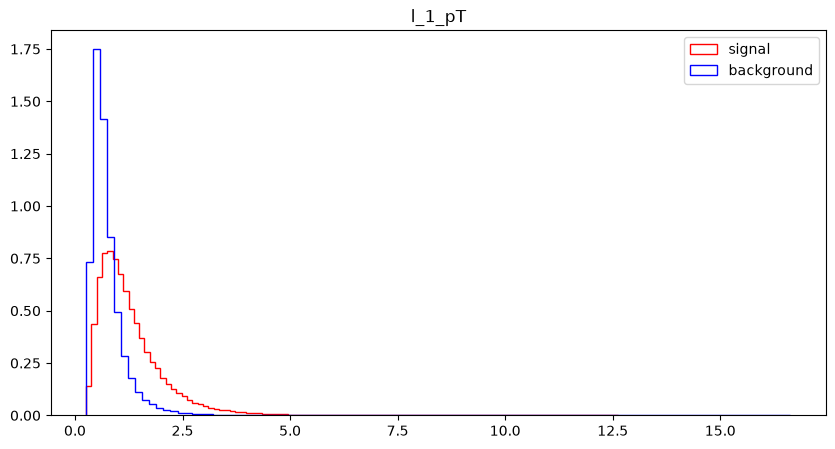

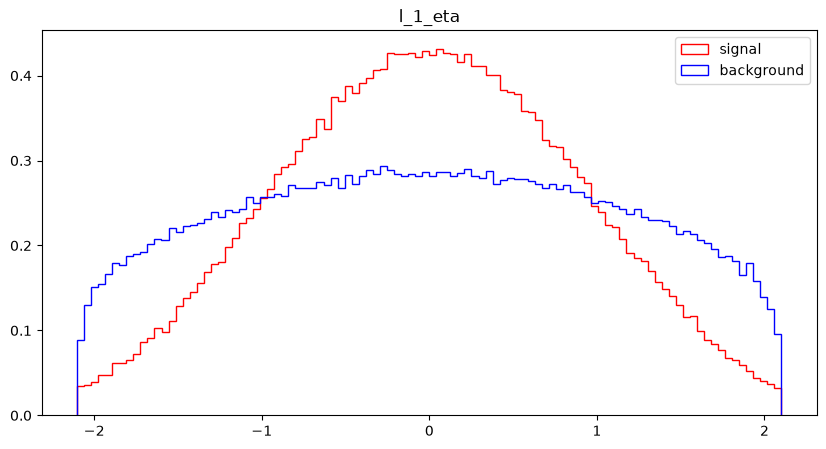

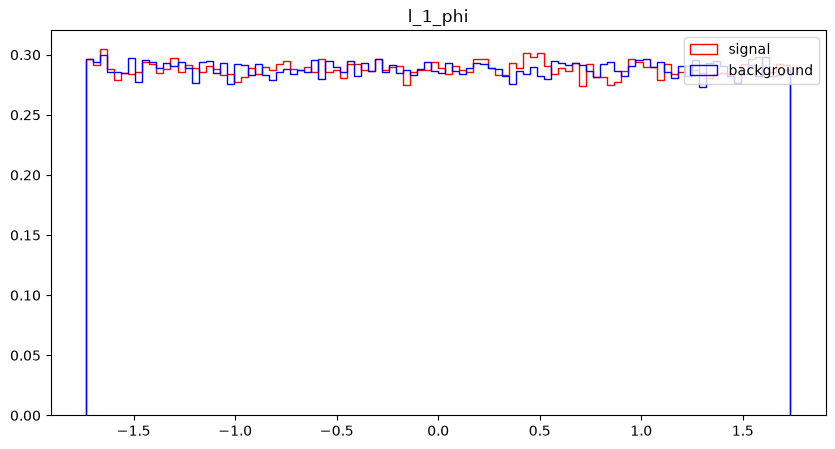

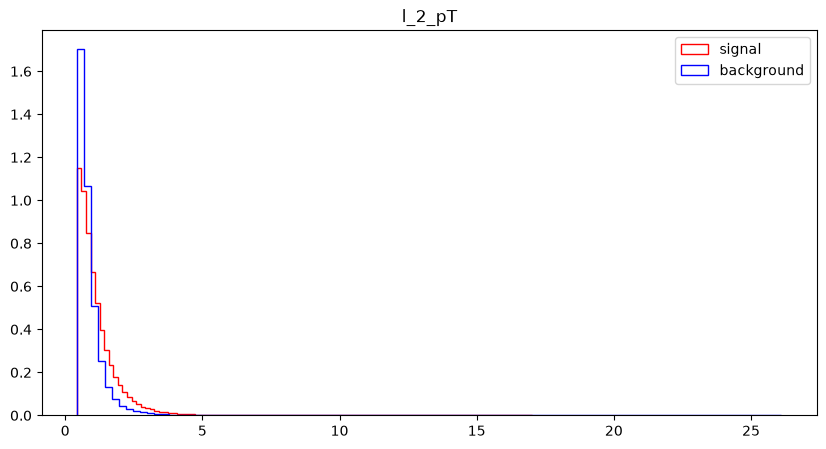

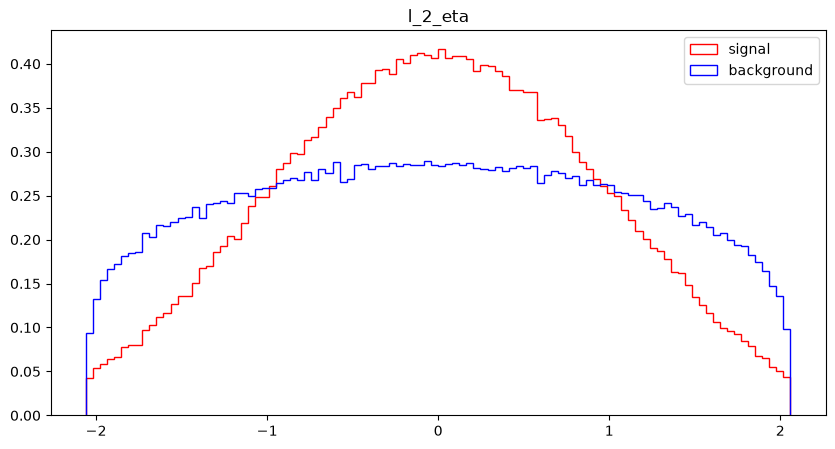

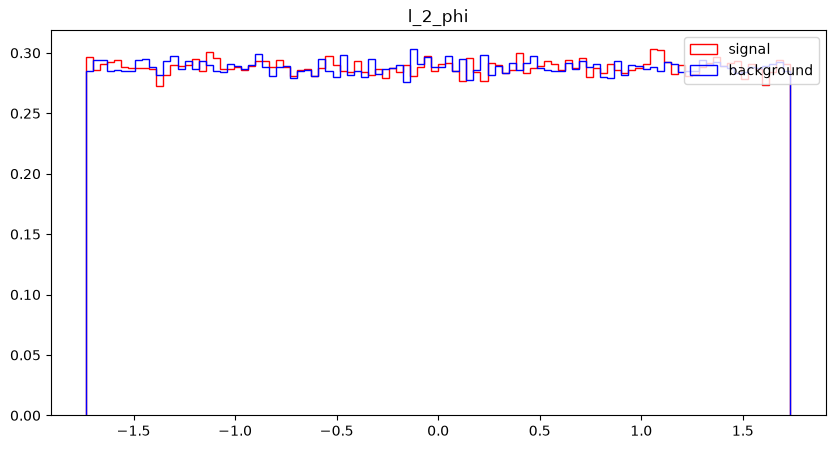

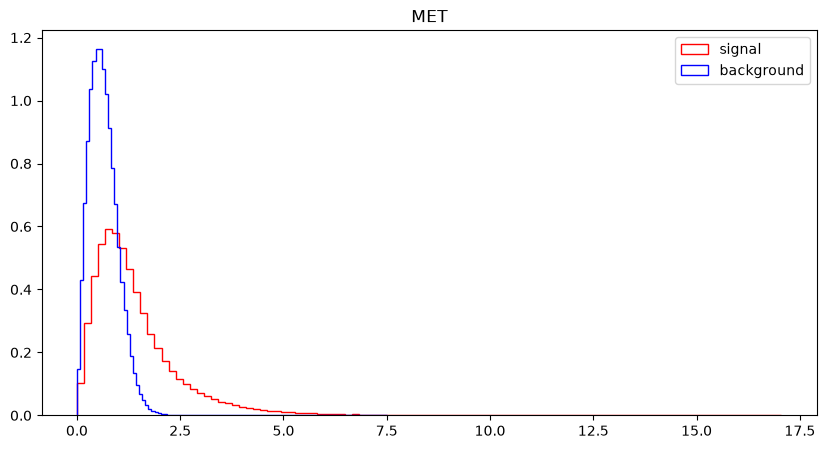

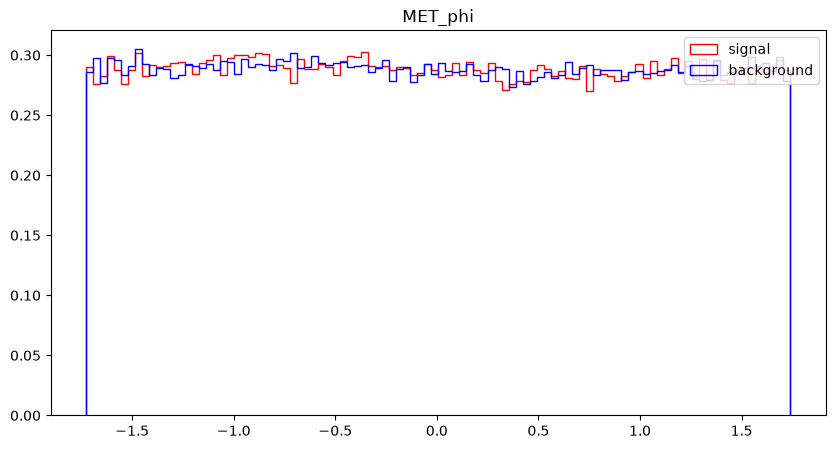

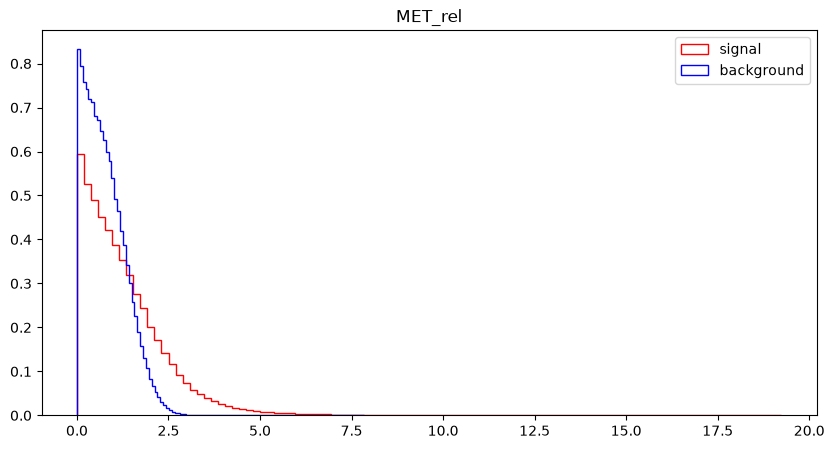

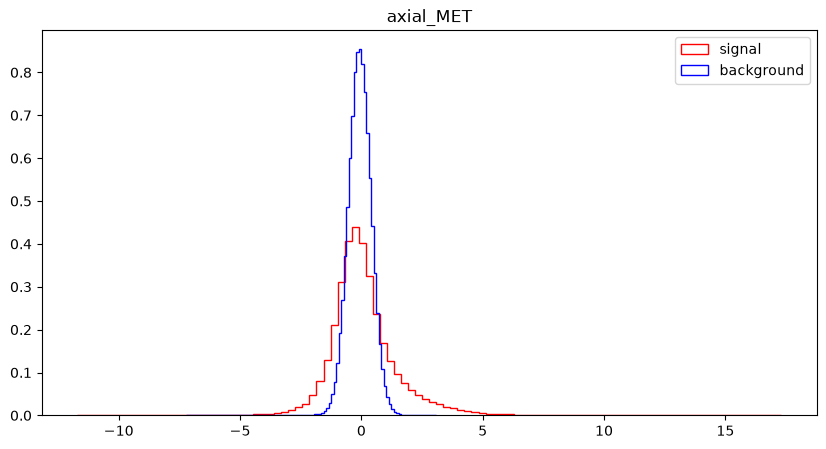

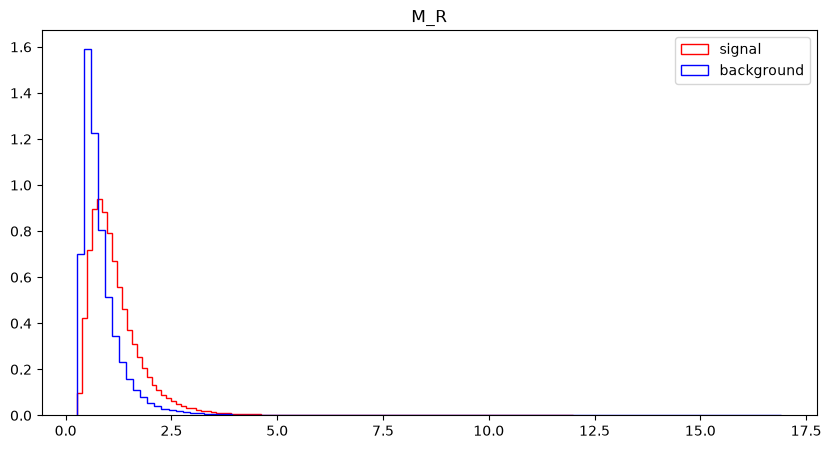

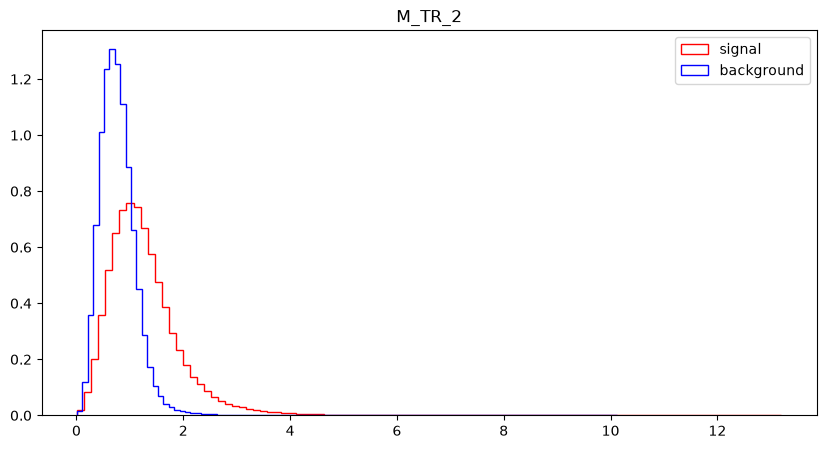

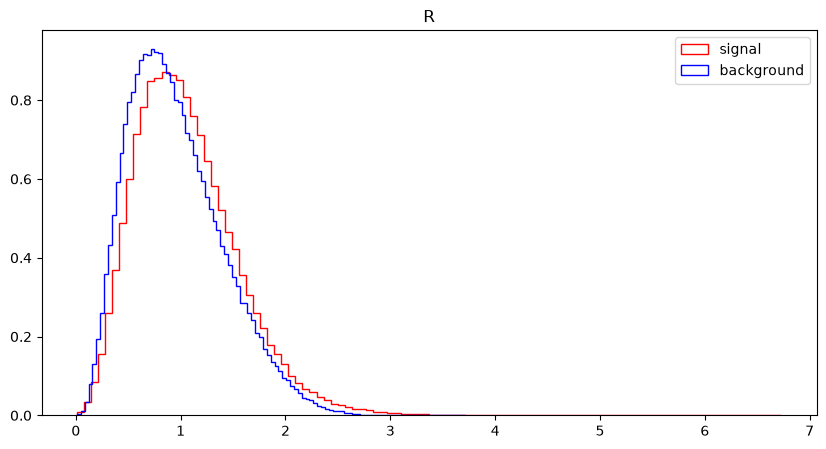

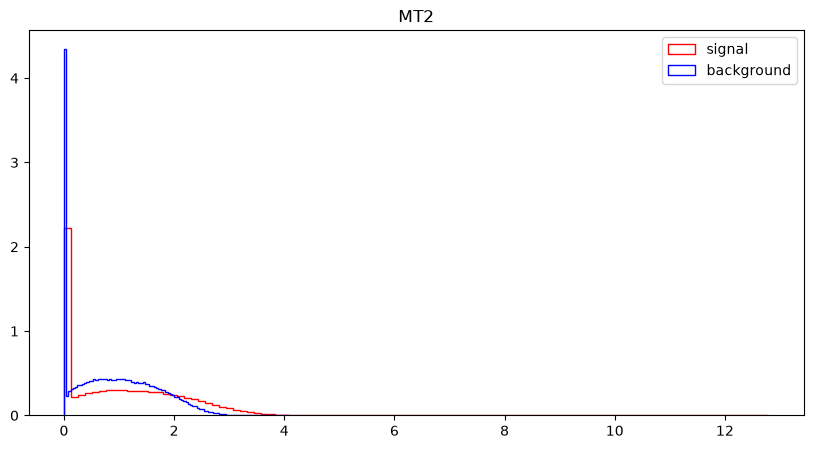

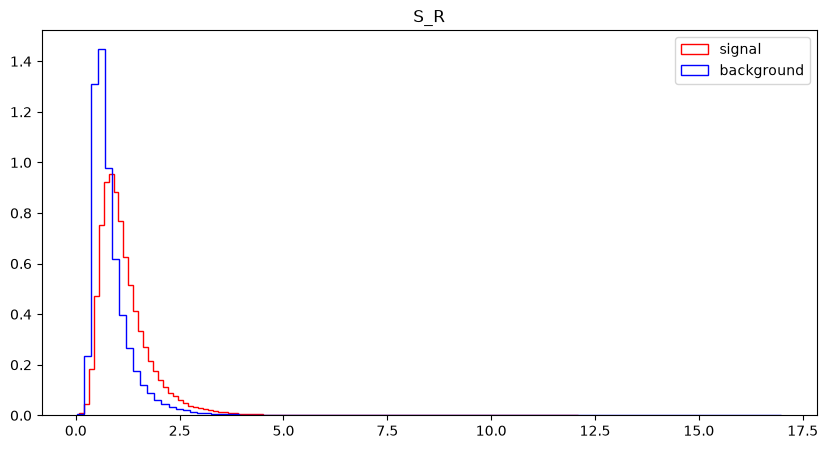

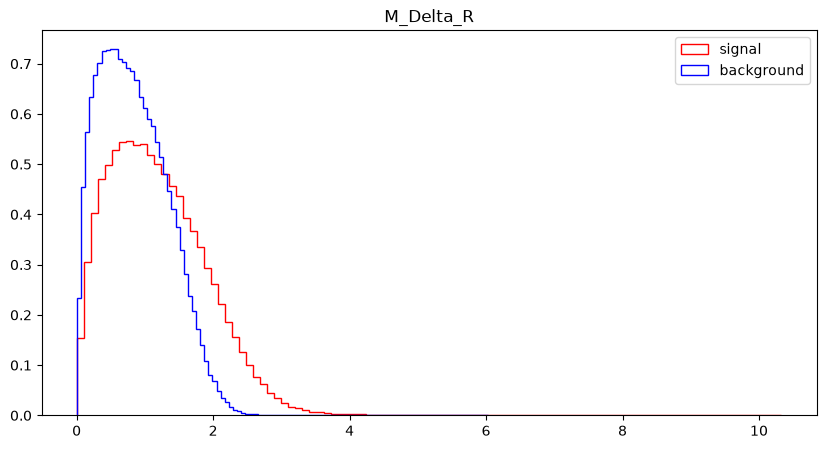

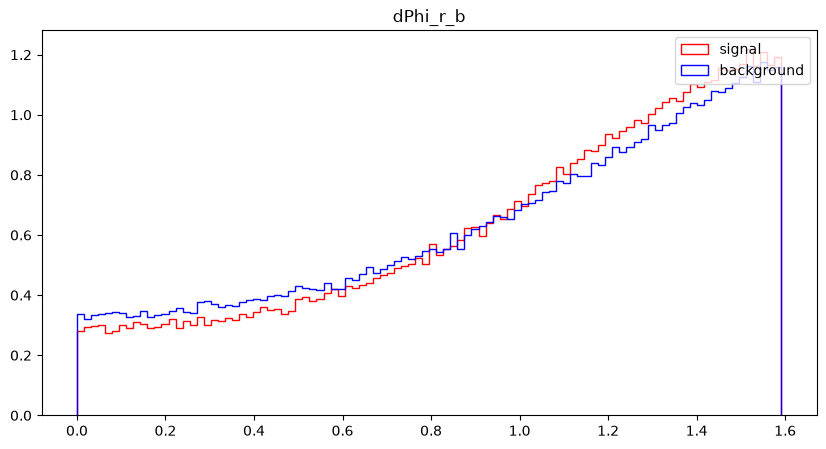

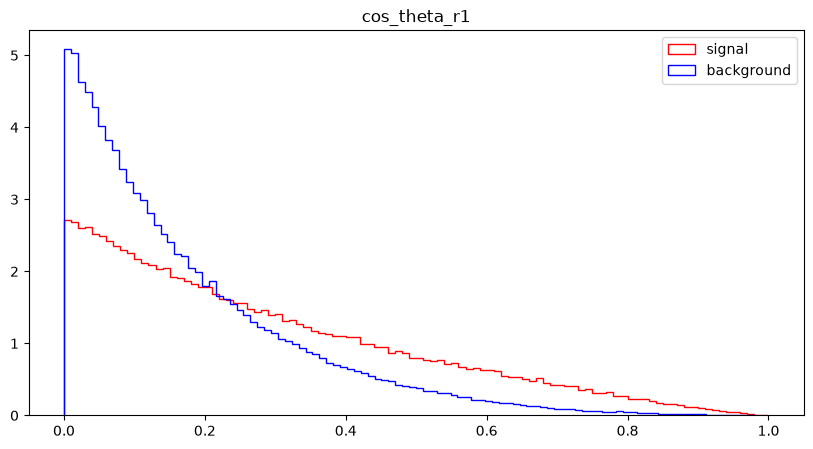

In [27]:
for var in VarNames[1:]:
    plt.figure(figsize=(10,5))
    plt.title(var)
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

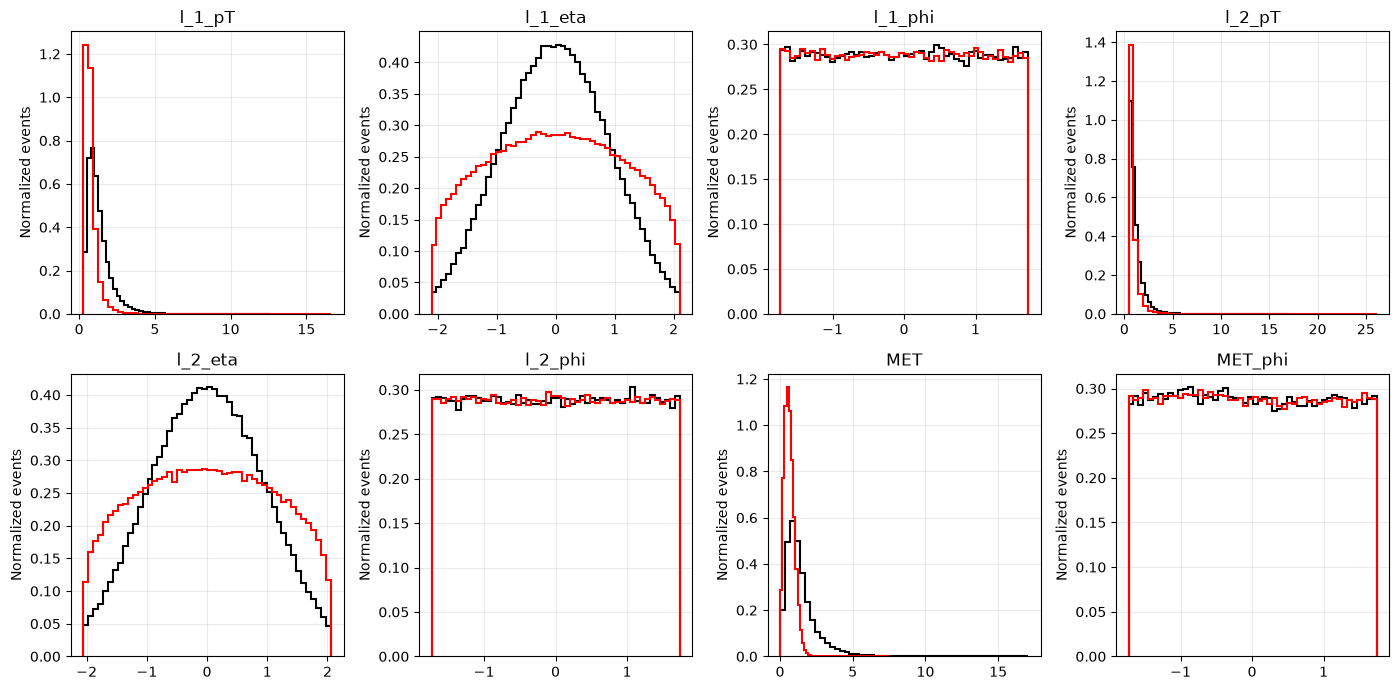

In [ ]:
#low level features
fig, axes = plt.subplots(nrows=2, ncols=4,figsize=(14, 7))
#used Ai here because I remembered you can make the plots into this segmented type thing just forgot the method
axes = axes.ravel() 

for ax, feature in zip(axes, RawNames):
    ax.hist(df_sig[feature],bins=50,density=True,histtype="step",linewidth=1.5,color="black",label="Signal", stacked=True)
    ax.hist(df_bkg[feature],bins=50,density=True,histtype="step",linewidth=1.5,color="red",label="Background", stacked=True)

    ax.set_title(feature)
    ax.set_ylabel("Normalized events")
    ax.grid(alpha=0.25)


plt.tight_layout()
plt.show()

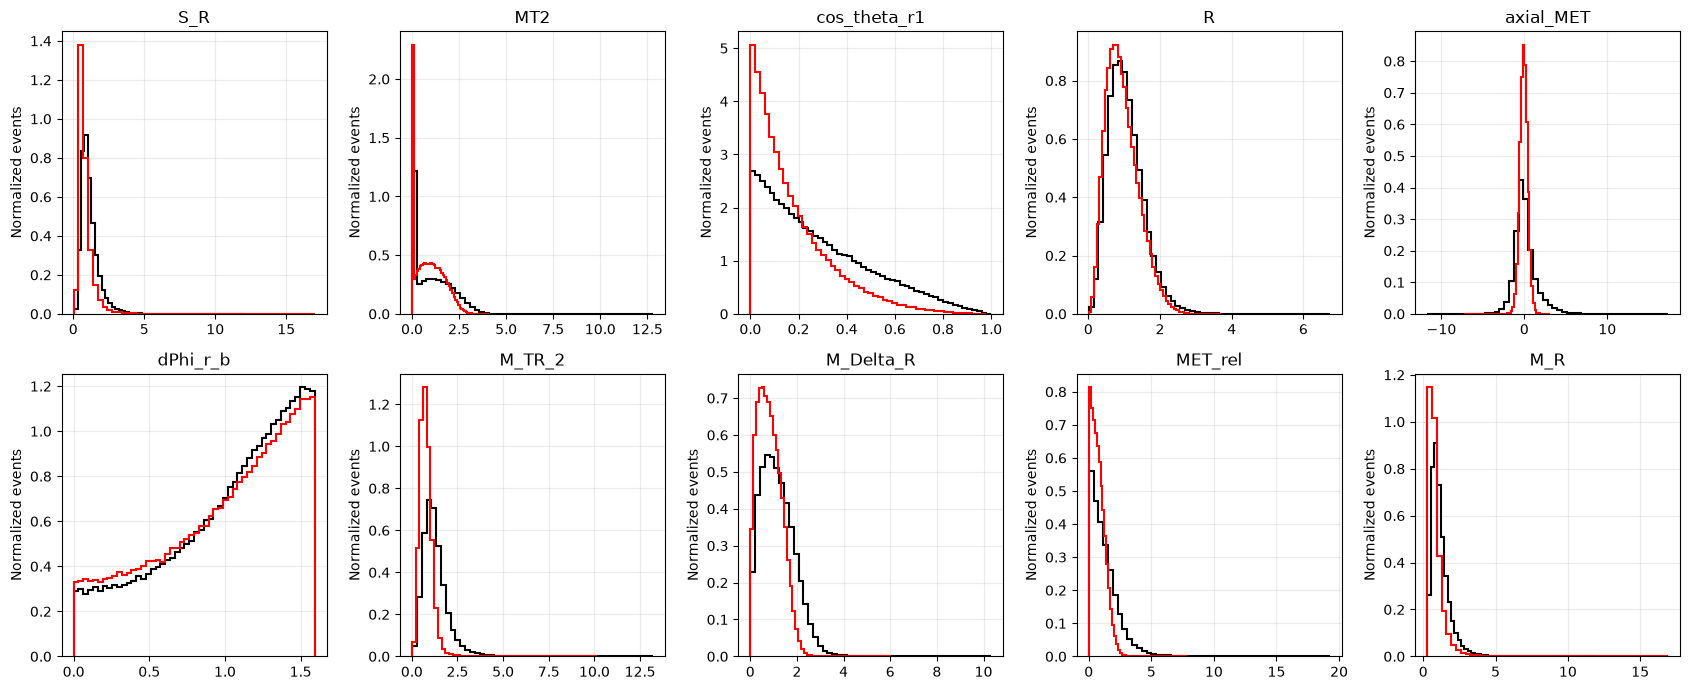

In [34]:
#high level features
fig, axes = plt.subplots(nrows=2, ncols=5,figsize=(17, 7))
axes = axes.ravel() 

for ax, feature in zip(axes, FeatureNames):
    ax.hist(df_sig[feature],bins=50,density=True,histtype="step",linewidth=1.5,color="black",label="Signal", stacked=True)
    ax.hist(df_bkg[feature],bins=50,density=True,histtype="step",linewidth=1.5,color="red",label="Background", stacked=True)

    ax.set_title(feature)
    ax.set_ylabel("Normalized events")
    ax.grid(alpha=0.25)


plt.tight_layout()
plt.show()


## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?
- I made edits to the compare_distributions functions. i called rasterized=True and s=1 to speed up the plotting by a lot
- I cannot think of a different method besides just using seaborn

#### Part c
Which observables appear to be best for separating signal from background?

- from the high level features the dphi_r_b variable seems to seperate signal and backgroudn very well
- from the low level features the met_phi variable seems to seperate signal and background well but less than dphi_r_b

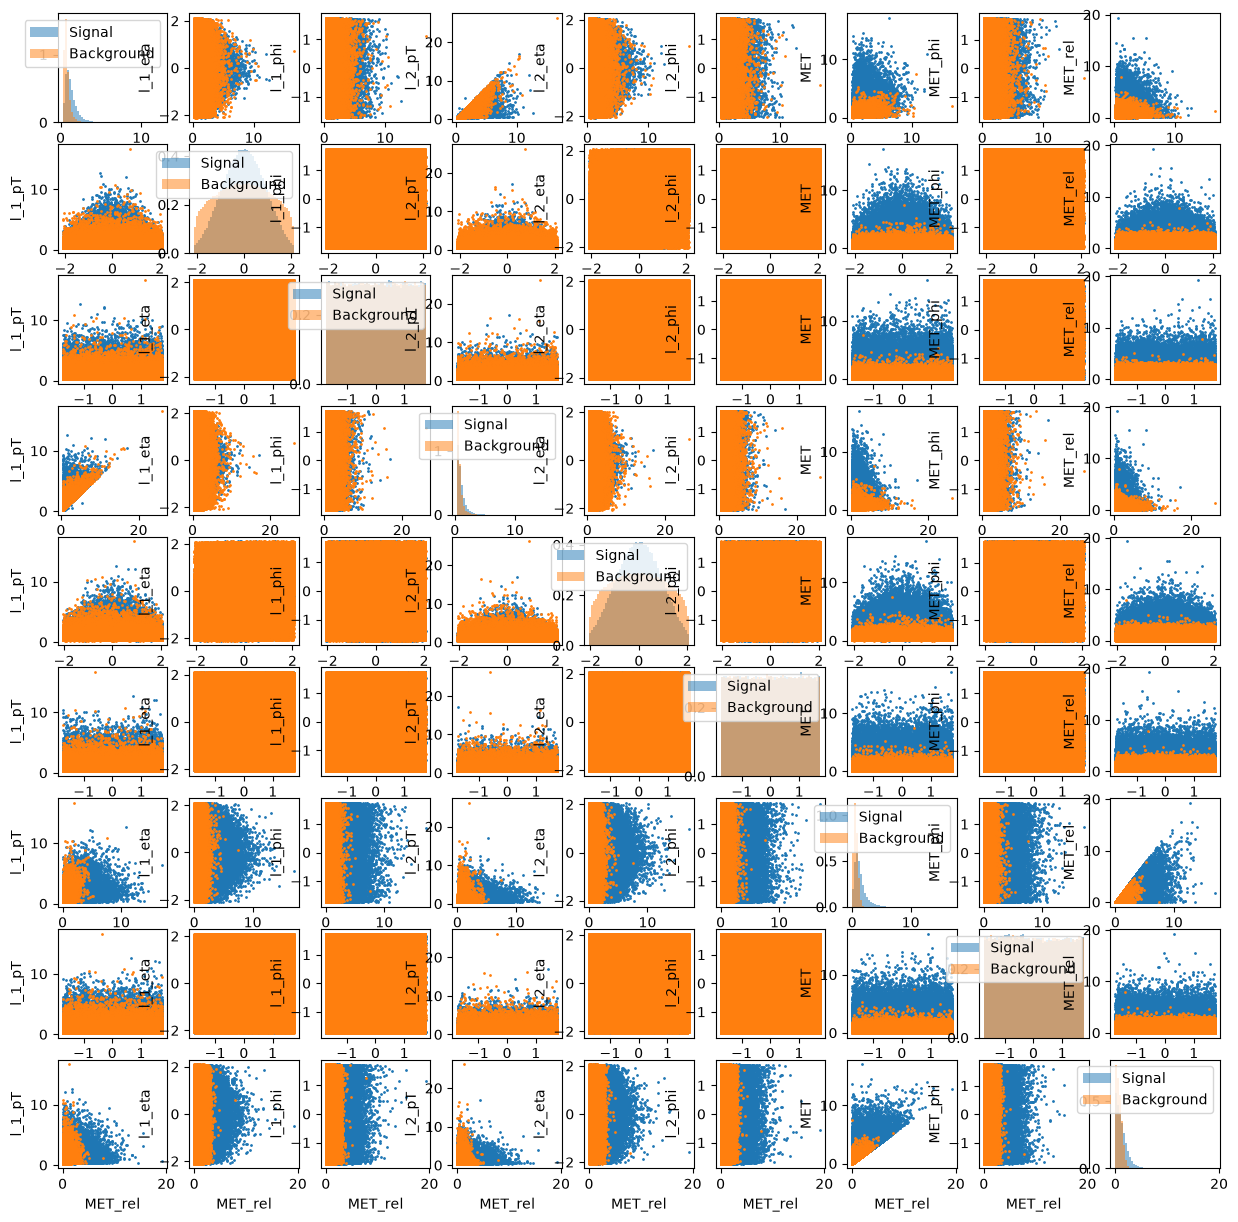

In [44]:
#4.1 part A Pair Plots for low level features
def create_pair_plot(df, columns, selections):
    n_columns=len(columns)
    plt.figure(figsize=(15,15))

    plot_i=0
    for i,x_var_name in enumerate(columns):
        for j,y_var_name in enumerate(columns):
            plot_i+=1
            plt.subplot(n_columns,n_columns,plot_i)
            make_legend = plot_i==1
            if i==j:
                compare_distributions(df,x_var_name,selections,alpha=0.5,density=1,bins=50,)
            else:
                compare_scatter(df,x_var_name,y_var_name,selections,make_legend=make_legend)

selection_dict = {"Signal": df.signal==1, "Background": df.signal==0}
columns = df.columns[1:10] #low level features
create_pair_plot(df, columns, selection_dict)

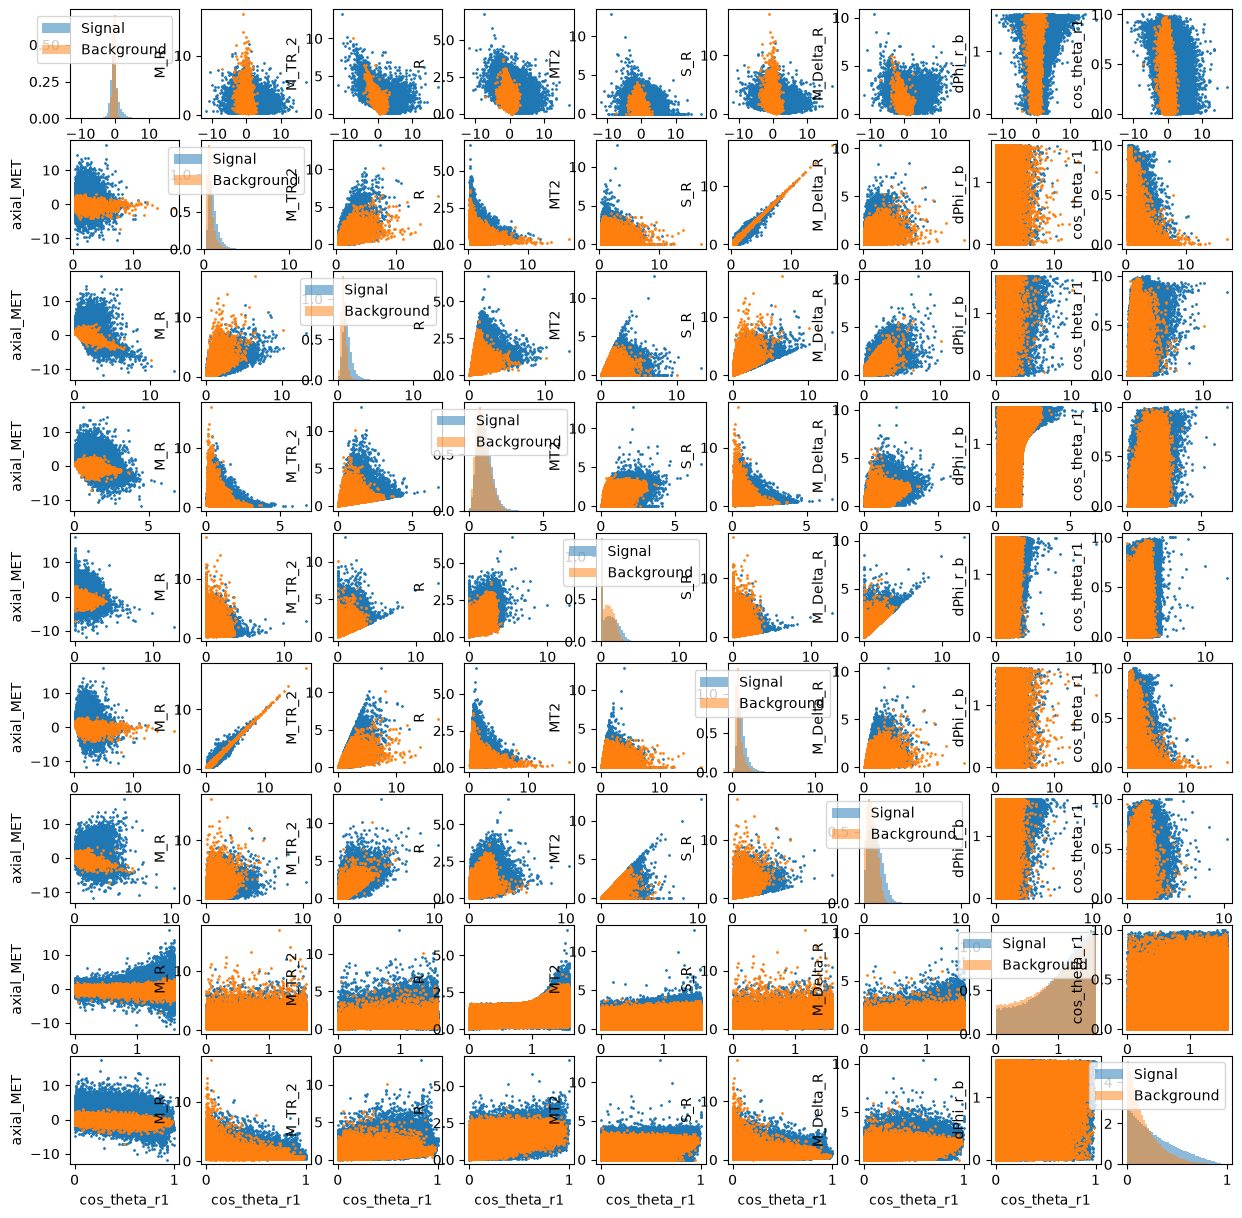

In [45]:
columns_high = df.columns[10:] #high level features
create_pair_plot(df, columns_high, selection_dict)

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

Hint: Example code for embedding a `tabulate` table into a notebook:

In [ ]:
# excercuse 4.2:

def show_cov_corr_matrix(df, headers, title):
    X = df[headers].to_numpy()

    cov = np.cov(X, rowvar=False)
    corr = np.corrcoef(X, rowvar=False)

    cov_df = pd.DataFrame(cov,index=headers,columns=headers)
    corr_df = pd.DataFrame(corr, index=headers, columns=headers)

    print(title)
    display(tabulate.tabulate(cov_df, tablefmt='html', headers=headers))
    print(title)
    display(tabulate.tabulate(corr_df, tablefmt='html', headers=headers))
    print()

show_cov_corr_matrix(df, RawNames, "Covariance and Correlation Matrices for Low-Level Features")
show_cov_corr_matrix(df, FeatureNames, "Covariance and Correlation Matrices for High-Level Features")

    




Covariance and Correlation Matrices for Low-Level Features


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467482,-0.000396674,7.66214e-05,0.305038,-0.000348827,0.000737337,0.228434,-0.000936714
l_1_eta,-0.000396674,1.0043,-0.000857631,-0.000162906,0.408313,-0.00104201,-0.00214698,-0.000588968
l_1_phi,7.66214e-05,-0.000857631,1.00397,0.00131296,0.000250715,-0.26681,0.000766366,-0.184804
l_2_pT,0.305038,-0.000162906,0.00131296,0.42549,-0.000575571,0.000155884,0.0794519,-0.00156177
l_2_eta,-0.000348827,0.408313,0.000250715,-0.000575571,1.00626,0.000441588,0.000381652,-0.000322449
l_2_phi,0.000737337,-0.00104201,-0.26681,0.000155884,0.000441588,1.0038,-0.000303976,-0.0354343
MET,0.228434,-0.00214698,0.000766366,0.0794519,0.000381652,-0.000303976,0.762249,-0.00279213
MET_phi,-0.000936714,-0.000588968,-0.184804,-0.00156177,-0.000322449,-0.0354343,-0.00279213,1.00331


Covariance and Correlation Matrices for Low-Level Features


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.000578921,0.000111842,0.683954,-0.000508594,0.00107637,0.382675,-0.00136775
l_1_eta,-0.000578921,1,-0.000854097,-0.000249206,0.406167,-0.00103781,-0.00245385,-0.000586735
l_1_phi,0.000111842,-0.000854097,1,0.00200884,0.000249438,-0.265777,0.000876046,-0.184133
l_2_pT,0.683954,-0.000249206,0.00200884,1,-0.000879627,0.000238525,0.139512,-0.00239031
l_2_eta,-0.000508594,0.406167,0.000249438,-0.000879627,1,0.000439378,0.000435776,-0.000320913
l_2_phi,0.00107637,-0.00103781,-0.265777,0.000238525,0.000439378,1,-0.00034751,-0.0353088
MET,0.382675,-0.00245385,0.000876046,0.139512,0.000435776,-0.00034751,1,-0.00319278
MET_phi,-0.00136775,-0.000586735,-0.184133,-0.00239031,-0.000320913,-0.0353088,-0.00319278,1



Covariance and Correlation Matrices for High-Level Features


,S_R,MT2,cos_theta_r1,R,axial_MET,dPhi_r_b,M_TR_2,M_Delta_R,MET_rel,M_R
S_R,0.382015,-0.0110375,-0.0103629,-0.0833587,-0.0413828,-0.00345651,0.228125,0.0957808,0.0823154,0.379763
MT2,-0.0110375,0.737661,0.0446289,0.2321,-0.460999,0.0208972,0.18917,0.432897,0.408779,-0.0365444
cos_theta_r1,-0.0103629,0.0446289,0.0388299,0.0581608,-0.0537349,0.00908347,0.0516659,0.0392089,0.0553179,-0.0143412
R,-0.0833587,0.2321,0.0581608,0.221578,-0.1809,0.0870914,0.104014,0.165483,0.248824,-0.112904
axial_MET,-0.0413828,-0.460999,-0.0537349,-0.1809,1.00537,-0.0251128,-0.185017,-0.233074,-0.119851,0.0171346
dPhi_r_b,-0.00345651,0.0208972,0.00908347,0.0870914,-0.0251128,0.190188,0.058133,0.0422407,0.146439,-0.0289617
M_TR_2,0.228125,0.18917,0.0516659,0.104014,-0.185017,0.058133,0.337827,0.241865,0.301993,0.209875
M_Delta_R,0.0957808,0.432897,0.0392089,0.165483,-0.233074,0.0422407,0.241865,0.388624,0.414743,0.07393
MET_rel,0.0823154,0.408779,0.0553179,0.248824,-0.119851,0.146439,0.301993,0.414743,0.790489,0.0436845
M_R,0.379763,-0.0365444,-0.0143412,-0.112904,0.0171346,-0.0289617,0.209875,0.07393,0.0436845,0.392167


Covariance and Correlation Matrices for High-Level Features


,S_R,MT2,cos_theta_r1,R,axial_MET,dPhi_r_b,M_TR_2,M_Delta_R,MET_rel,M_R
S_R,1,-0.0207923,-0.085086,-0.286515,-0.0667754,-0.0128235,0.635017,0.248584,0.149794,0.981155
MT2,-0.0207923,1,0.263697,0.574095,-0.535313,0.0557916,0.378944,0.808521,0.535318,-0.0679449
cos_theta_r1,-0.085086,0.263697,1,0.627024,-0.271963,0.1057,0.4511,0.31918,0.315743,-0.116216
R,-0.286515,0.574095,0.627024,1,-0.383276,0.424248,0.380174,0.56393,0.594539,-0.383011
axial_MET,-0.0667754,-0.535313,-0.271963,-0.383276,1,-0.0574301,-0.317468,-0.372877,-0.134441,0.0272881
dPhi_r_b,-0.0128235,0.0557916,0.1057,0.424248,-0.0574301,1,0.229342,0.155372,0.377675,-0.106046
M_TR_2,0.635017,0.378944,0.4511,0.380174,-0.317468,0.229342,1,0.667515,0.584388,0.576603
M_Delta_R,0.248584,0.808521,0.31918,0.56393,-0.372877,0.155372,0.667515,1,0.748284,0.189374
MET_rel,0.149794,0.535318,0.315743,0.594539,-0.134441,0.377675,0.584388,0.748284,1,0.0784593
M_R,0.981155,-0.0679449,-0.116216,-0.383011,0.0272881,-0.106046,0.576603,0.189374,0.0784593,1


## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 